# Практическая работа 5. Оценка RAG (RAGAS)

Выполнены задания:

1. Проверка работы RAG с записью результатов в датасет.
2. Эксперименты с RAG: длина чанков и эмбеддеры.

Используемые модели работают локально:
- языковая модель SmolLM2-135M-Instruct через `llama-cpp-python` (генерирует ответы);
- эмбеддеры WordLlama и TF-IDF.

Модель понимает в основном английский язык, поэтому документы и вопросы на английском.

In [1]:
# pip install llama-cpp-python llm-smollm2 wordllama scikit-learn pandas numpy datasets ragas rapidfuzz "langchain-community<0.4"

In [2]:
import os, re, time, ctypes, importlib.util, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import llama_cpp
from llama_cpp import Llama
import wordllama
from wordllama import WordLlama
from sklearn.feature_extraction.text import TfidfVectorizer
from datasets import Dataset

warnings.filterwarnings("ignore")

@llama_cpp.llama_log_callback
def quiet_log(level, text, user_data):
    pass
llama_cpp.llama_log_set(quiet_log, ctypes.c_void_p())

MODEL_PATH = os.path.join(importlib.util.find_spec("llm_smollm2").submodule_search_locations[0],
                          "SmolLM2-135M-Instruct.Q4_1.gguf")
llm = Llama(MODEL_PATH, n_ctx=2048, verbose=False)
wl = WordLlama.load(cache_dir=Path(wordllama.__file__).parent, disable_download=True)

def rag_answer(question, contexts):
    context = "\n".join(contexts)
    r = llm.create_chat_completion(messages=[
        {"role": "system", "content": "Answer the question using only the context. Answer in one sentence."},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}],
        max_tokens=60, temperature=0, seed=0)
    return r["choices"][0]["message"]["content"].strip()

## Данные
Четыре документа о вымышленном городе и 8 вопросов. Для каждого вопроса есть эталонный ответ (`ground_truth`), исходный документ, ключевой факт (по нему видно, что чанк содержит нужную информацию) и ключевое слово для проверки ответа.

In [3]:
DOCUMENTS = {
    "museum": (
        "The Lakeview History Museum is located in the old fire station on Mill Street. "
        "It was founded in 1972 by a group of local teachers. "
        "The museum is open from Tuesday to Sunday, from 10 am to 5 pm, and it is closed on Mondays. "
        "A ticket for adults costs 6 dollars, and children under 12 enter for free. "
        "The main hall shows the history of the fishing industry on the lake. "
        "On the second floor there is a collection of old cameras and photographs of the town. "
        "Every first Friday of the month the museum stays open until 9 pm and offers free guided tours."),
    "transport": (
        "Public transport in Lakeview consists of four bus lines and one ferry. "
        "Buses run every 15 minutes during the day and every 30 minutes after 8 pm. "
        "A single ticket costs 2 dollars and is valid for 60 minutes, including transfers. "
        "A monthly pass costs 40 dollars, and students pay half price. "
        "The ferry crosses the lake to the village of Pinewood four times a day. "
        "The first ferry leaves at 7 am and the last one at 6 pm. "
        "Bicycles can be taken on the ferry for an extra 1 dollar."),
    "festival": (
        "The Lakeview Summer Festival takes place every year on the second weekend of July. "
        "It started in 1985 as a small fish market and is now the biggest event in the region. "
        "The festival includes concerts on the beach, a boat race and a food fair. "
        "The boat race starts on Sunday at noon and usually has about forty teams. "
        "Entrance to the festival is free, but concerts in the evening require a ticket of 15 dollars. "
        "Around twenty thousand visitors come to the festival every year. "
        "Fireworks over the lake close the festival on Sunday night."),
    "park": (
        "Green Hill Park is the largest park in Lakeview and covers 120 hectares. "
        "It has a lake for swimming, three playgrounds and a small zoo with farm animals. "
        "Barbecue is allowed only in special zones near the north entrance. "
        "Dogs must be kept on a leash everywhere in the park. "
        "In winter the main alley becomes a skating rink, and skates can be rented for 5 dollars. "
        "The park is open all day, but the zoo works only from 9 am to 6 pm. "
        "Parking near the south entrance costs 3 dollars per day."),
}

QA = [
    {"question": "On which day is the history museum closed?", "ground_truth": "The museum is closed on Mondays.",
     "doc": "museum", "fact": "closed on Mondays", "key": "monday"},
    {"question": "How much is an adult ticket to the museum?", "ground_truth": "An adult ticket costs 6 dollars.",
     "doc": "museum", "fact": "costs 6 dollars", "key": "6 dollars"},
    {"question": "How long is a single bus ticket valid?", "ground_truth": "A single ticket is valid for 60 minutes.",
     "doc": "transport", "fact": "valid for 60 minutes", "key": "60 minutes"},
    {"question": "When does the last ferry leave?", "ground_truth": "The last ferry leaves at 6 pm.",
     "doc": "transport", "fact": "last one at 6 pm", "key": "6 pm"},
    {"question": "When does the boat race start?", "ground_truth": "The boat race starts on Sunday at noon.",
     "doc": "festival", "fact": "Sunday at noon", "key": "noon"},
    {"question": "How much does a ticket for the evening concerts cost?",
     "ground_truth": "A ticket for the evening concerts costs 15 dollars.", "doc": "festival", "fact": "15 dollars", "key": "15 dollars"},
    {"question": "Where is barbecue allowed in the park?",
     "ground_truth": "Barbecue is allowed only in special zones near the north entrance.", "doc": "park",
     "fact": "near the north entrance", "key": "north entrance"},
    {"question": "How much does it cost to rent skates?", "ground_truth": "Skates can be rented for 5 dollars.",
     "doc": "park", "fact": "rented for 5 dollars", "key": "5 dollars"},
]

## Задание 1. RAG с записью результатов в датасет

### 1.1. Подготовка вопросов и контекстов
Для каждого вопроса контекстом служат два абзаца: нужный и один посторонний. Так проверяется, умеет ли модель выбрать нужную информацию.

In [4]:
names = list(DOCUMENTS)
for i, item in enumerate(QA):
    other = names[(names.index(item["doc"]) + 1) % len(names)]
    item["contexts"] = [DOCUMENTS[item["doc"]], DOCUMENTS[other]]

### 1.2. Прогон через RAG и сохранение в `Dataset`

In [5]:
records = {"question": [], "contexts": [], "answer": [], "ground_truth": []}
for item in QA:
    records["question"].append(item["question"])
    records["contexts"].append(item["contexts"])
    records["answer"].append(rag_answer(item["question"], item["contexts"]))
    records["ground_truth"].append(item["ground_truth"])

dataset = Dataset.from_dict(records)
dataset

Dataset({
    features: ['question', 'contexts', 'answer', 'ground_truth'],
    num_rows: 8
})

In [6]:
df = dataset.to_pandas()
pd.set_option("display.max_colwidth", 100)
df[["question", "answer", "ground_truth"]]

,question,answer,ground_truth
0,On which day is the history museum closed?,"The history museum is closed on Tuesday, from 10 am to 5 pm, and on Sunday, from 10 am to 5 pm.",The museum is closed on Mondays.
1,How much is an adult ticket to the museum?,The answer is: 6.50. The ticket to the Lakeview History Museum is 6.50 dollars.,An adult ticket costs 6 dollars.
2,How long is a single bus ticket valid?,A single bus ticket valid for 15 minutes is 15 minutes.,A single ticket is valid for 60 minutes.
3,When does the last ferry leave?,The last ferry leaves on July 15th.,The last ferry leaves at 6 pm.
4,When does the boat race start?,The boat race starts on Sunday at noon.,The boat race starts on Sunday at noon.
5,How much does a ticket for the evening concerts cost?,"A ticket for the evening concerts costs 15 dollars, and the ticket is available for 10 dollars p...",A ticket for the evening concerts costs 15 dollars.
6,Where is barbecue allowed in the park?,"The Lakeview History Museum is located in the old fire station on Mill Street, which is a histor...",Barbecue is allowed only in special zones near the north entrance.
7,How much does it cost to rent skates?,The answer is: 6.50. The cost to rent skates is 6.50 dollars.,Skates can be rented for 5 dollars.


### 1.3. Проверка корректности
Проверяется, что нет пустых значений, у каждого вопроса есть контексты, а типы данных правильные.

In [7]:
checks = {
    "строк": len(df),
    "пустых значений": int(df.isna().sum().sum()),
    "пустых ответов": int((df["answer"].str.strip() == "").sum()),
    "контексты - списки строк": all(isinstance(c, (list, np.ndarray)) and all(isinstance(x, str) for x in c)
                                    for c in df["contexts"]),
    "контекстов на вопрос": sorted(set(len(c) for c in df["contexts"])),
}
checks

{'строк': 8,
 'пустых значений': 0,
 'пустых ответов': 0,
 'контексты - списки строк': True,
 'контекстов на вопрос': [2]}

### 1.4. Метрики RAGAS
Метрики faithfulness и answer relevancy в RAGAS считаются с помощью LLM-судьи. Платные модели для этого не использовались, а SmolLM2 слишком мала, чтобы быть судьей (она не выдает ответ в нужном формате). Поэтому через RAGAS посчитаны метрики, которым LLM не нужна:
- `non_llm_context_precision_with_reference`: насколько найденные контексты похожи на эталонный абзац (с учетом порядка);
- `non_llm_context_recall`: найден ли эталонный абзац среди контекстов;
- `non_llm_string_similarity`: похожесть ответа на эталонный ответ (по расстоянию Левенштейна, от 0 до 1).

In [8]:
from ragas import evaluate, EvaluationDataset
from ragas.metrics import NonLLMContextPrecisionWithReference, NonLLMContextRecall, NonLLMStringSimilarity

eval_data = EvaluationDataset.from_list([
    {"user_input": r["question"], "retrieved_contexts": list(r["contexts"]), "response": r["answer"],
     "reference": r["ground_truth"], "reference_contexts": [DOCUMENTS[item["doc"]]]}
    for r, item in zip(df.to_dict("records"), QA)])

ragas_result = evaluate(eval_data, metrics=[NonLLMContextPrecisionWithReference(), NonLLMContextRecall(),
                                            NonLLMStringSimilarity()], show_progress=False)
ragas_result

{'non_llm_context_precision_with_reference': 1.0000, 'non_llm_context_recall': 1.0000, 'non_llm_string_similarity': 0.5080}

In [9]:
scores = ragas_result.to_pandas()
df_full = df.join(scores[["non_llm_context_precision_with_reference", "non_llm_context_recall",
                          "non_llm_string_similarity"]])
df_full[["question", "answer", "non_llm_context_precision_with_reference", "non_llm_string_similarity"]]

,question,answer,non_llm_context_precision_with_reference,non_llm_string_similarity
0,On which day is the history museum closed?,"The history museum is closed on Tuesday, from 10 am to 5 pm, and on Sunday, from 10 am to 5 pm.",1.0,0.315789
1,How much is an adult ticket to the museum?,The answer is: 6.50. The ticket to the Lakeview History Museum is 6.50 dollars.,1.0,0.316456
2,How long is a single bus ticket valid?,A single bus ticket valid for 15 minutes is 15 minutes.,1.0,0.581818
3,When does the last ferry leave?,The last ferry leaves on July 15th.,1.0,0.714286
4,When does the boat race start?,The boat race starts on Sunday at noon.,1.0,1.000000
5,How much does a ticket for the evening concerts cost?,"A ticket for the evening concerts costs 15 dollars, and the ticket is available for 10 dollars p...",1.0,0.481132
6,Where is barbecue allowed in the park?,"The Lakeview History Museum is located in the old fire station on Mill Street, which is a histor...",1.0,0.277778
7,How much does it cost to rent skates?,The answer is: 6.50. The cost to rent skates is 6.50 dollars.,1.0,0.377049


In [10]:
df_full.to_csv("rag_results.csv", index=False)
print(pd.read_csv("rag_results.csv").shape)

(8, 7)


**Вывод по заданию 1.** Датасет из 8 строк собран и прошел проверку: пустых значений нет, у каждого вопроса два контекста. Метрики контекста равны 1, так как нужный абзац всегда был среди контекстов и стоял первым (контексты подготовлены заранее). Проблема в генерации: верно ответить удалось только на 2 вопроса из 8 (время начала гонки и цена билета на концерт). Модель путает факты из соседних предложений (называет цену 6,50 вместо 6 долларов, срок 15 минут вместо 60) и иногда берет ответ из постороннего абзаца (вопрос о барбекю получил ответ про музей). Средняя похожесть ответа на эталон 0,51. Значит, слабое место этого RAG не поиск, а слишком маленькая модель генерации.

Загрузка датасета в Langfuse не выполнялась, так как для этого нужен аккаунт и ключи внешнего сервиса. Результаты сохранены в файл `rag_results.csv`, который можно загрузить в Langfuse позже.

## Задание 2. Длина чанков и эмбеддеры

### 2.1. Чанки трех размеров
Текст делится на чанки по границам предложений. Предложения добавляются в чанк, пока его длина не превысит заданный размер.

In [11]:
def split_text(text, size):
    sentences = re.split(r"(?<=\.) ", text)
    chunks, current = [], ""
    for s in sentences:
        if current and len(current) + len(s) + 1 > size:
            chunks.append(current)
            current = s
        else:
            current = (current + " " + s).strip()
    if current:
        chunks.append(current)
    return chunks

CHUNK_SIZES = {"маленькие": 120, "средние": 300, "большие": 700}
chunk_sets = {}
for label, size in CHUNK_SIZES.items():
    chunk_sets[label] = [c for text in DOCUMENTS.values() for c in split_text(text, size)]
    lengths = [len(c) for c in chunk_sets[label]]
    print(f"{label}: {len(lengths)} чанков, средняя длина {np.mean(lengths):.0f} символов")

маленькие: 26 чанков, средняя длина 78 символов
средние: 8 чанков, средняя длина 255 символов
большие: 4 чанков, средняя длина 512 символов


### 2.2. Эмбеддеры и поиск
Поиск возвращает 2 самых похожих чанка по косинусной близости. Для больших чанков это половина базы, для маленьких меньше десятой части.

In [12]:
class WordLlamaEmbedder:
    def fit(self, chunks):
        self.matrix = wl.embed(chunks, norm=True)
        return self
    def query(self, text):
        return wl.embed([text], norm=True)[0]

class TfidfEmbedder:
    def fit(self, chunks):
        self.vectorizer = TfidfVectorizer(stop_words="english").fit(chunks)
        self.matrix = self.vectorizer.transform(chunks).toarray()
        return self
    def query(self, text):
        return self.vectorizer.transform([text]).toarray()[0]

EMBEDDERS = {"WordLlama": WordLlamaEmbedder, "TF-IDF": TfidfEmbedder}

def search(index, chunks, question, k=2):
    q = index.query(question)
    sims = index.matrix @ q / (np.linalg.norm(index.matrix, axis=1) * np.linalg.norm(q) + 1e-9)
    return [chunks[i] for i in np.argsort(-sims)[:k]]

### 2.3. Метрики
В этом задании контексты разной длины, поэтому метрики RAGAS без LLM, основанные на похожести строк, дают несправедливый результат: маленький чанк сильно отличается от целого эталонного абзаца, даже если содержит ответ. Поэтому метрики посчитаны по формулам RAGAS, но вместо LLM-судьи используются простые правила:
- **context precision**: чанк считается релевантным, если содержит ключевой факт; учитывается позиция релевантных чанков (как в RAGAS);
- **context recall**: есть ли ключевой факт хотя бы в одном найденном чанке;
- **faithfulness**: доля значимых слов ответа, которые встречаются в найденных контекстах;
- **answer relevancy**: косинусная близость вопроса и ответа по эмбеддингам WordLlama.

Дополнительно считается доля верных ответов: ответ верный, если в нем есть ключевое слово эталона.

In [13]:
STOP = set(TfidfVectorizer(stop_words="english").get_stop_words())

def words(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

def context_precision(contexts, fact):
    rel = [fact.lower() in c.lower() for c in contexts]
    if not any(rel):
        return 0.0
    return sum(sum(rel[:k + 1]) / (k + 1) for k in range(len(rel)) if rel[k]) / sum(rel)

def context_recall(contexts, fact):
    return float(any(fact.lower() in c.lower() for c in contexts))

def faithfulness(answer, contexts):
    ans = words(answer)
    ctx = set(words(" ".join(contexts)))
    return sum(w in ctx for w in ans) / len(ans) if ans else 0.0

def answer_relevancy(question, answer):
    q, a = wl.embed([question, answer], norm=True)
    return float(q @ a)

### 2.4. Прогон всех комбинаций

In [14]:
rows = []
for chunk_label, chunks in chunk_sets.items():
    for emb_name, emb_cls in EMBEDDERS.items():
        index = emb_cls().fit(chunks)
        for item in QA:
            t = time.perf_counter(); contexts = search(index, chunks, item["question"]); t_search = time.perf_counter() - t
            t = time.perf_counter(); answer = rag_answer(item["question"], contexts); t_gen = time.perf_counter() - t
            rows.append({"чанки": chunk_label, "эмбеддер": emb_name, "question": item["question"],
                         "contexts": contexts, "answer": answer, "ground_truth": item["ground_truth"],
                         "поиск, мс": t_search * 1000, "генерация, с": t_gen,
                         "context_precision": context_precision(contexts, item["fact"]),
                         "context_recall": context_recall(contexts, item["fact"]),
                         "faithfulness": faithfulness(answer, contexts),
                         "answer_relevancy": answer_relevancy(item["question"], answer),
                         "верный ответ": bool(re.search(r"\b" + item["key"] + r"\b", answer.lower()))})
exp = pd.DataFrame(rows)
exp.to_csv("rag_experiments.csv", index=False)
exp[["чанки", "эмбеддер", "question", "answer"]].head(8)

,чанки,эмбеддер,question,answer
0,маленькие,WordLlama,On which day is the history museum closed?,"The museum is closed on Tuesday from 10 am to 5 pm, and it is open on Mondays from 10 am to 5 pm."
1,маленькие,WordLlama,How much is an adult ticket to the museum?,The answer is: 6.66666666666667.
2,маленькие,WordLlama,How long is a single bus ticket valid?,"A single bus ticket is valid for 60 minutes, and a single concert ticket requires a 15 dollar fee."
3,маленькие,WordLlama,When does the last ferry leave?,The last ferry leaves at 6 pm.
4,маленькие,WordLlama,When does the boat race start?,"The boat race usually starts on Sunday at noon, but it can also start at any time during the fes..."
5,маленькие,WordLlama,How much does a ticket for the evening concerts cost?,A single ticket for the evening concerts costs 2 dollars.
6,маленькие,WordLlama,Where is barbecue allowed in the park?,The answer is: Green Hill Park is the largest park in Lakeview and covers 120 hectares.
7,маленькие,WordLlama,How much does it cost to rent skates?,The answer is: 40.


### 2.5. Сравнение

In [15]:
metrics_cols = ["context_precision", "context_recall", "faithfulness", "answer_relevancy", "верный ответ",
                "поиск, мс", "генерация, с"]
summary = exp.groupby(["чанки", "эмбеддер"], sort=False)[metrics_cols].mean().round(3)
summary

context_precision  context_recall  faithfulness  \
чанки     эмбеддер                                                     
маленькие WordLlama              1.000             1.0         0.766   
          TF-IDF                 0.938             1.0         0.772   
средние   WordLlama              0.938             1.0         0.698   
          TF-IDF                 0.938             1.0         0.667   
большие   WordLlama              1.000             1.0         0.854   
          TF-IDF                 1.000             1.0         0.804   

                     answer_relevancy  верный ответ  поиск, мс  генерация, с  
чанки     эмбеддер                                                            
маленькие WordLlama             0.526         0.375      0.266         0.327  
          TF-IDF                0.547         0.500      0.936         0.304  
средние   WordLlama             0.594         0.250      0.197         0.458  
          TF-IDF                0.586         0.250      0.893         0.436  
большие   WordLlama             0.676         0.375      0.188         0.683  
          TF-IDF                0.683         0.250      0.868         0.627

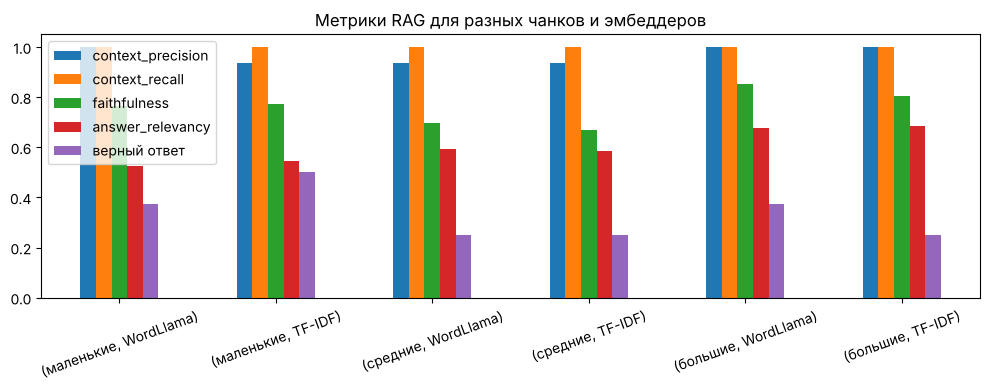

In [16]:
import matplotlib.pyplot as plt

ax = summary[["context_precision", "context_recall", "faithfulness", "answer_relevancy", "верный ответ"]].plot.bar(figsize=(10, 4))
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_title("Метрики RAG для разных чанков и эмбеддеров")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 2.6. Ответы на один вопрос при разных настройках

In [17]:
exp[exp["question"] == QA[3]["question"]][["чанки", "эмбеддер", "answer"]]

,чанки,эмбеддер,answer
3,маленькие,WordLlama,The last ferry leaves at 6 pm.
11,маленькие,TF-IDF,The last ferry leaves at 6 pm.
19,средние,WordLlama,The last ferry leaves at 6:15 pm.
27,средние,TF-IDF,The last ferry leaves at 6:15 pm.
35,большие,WordLlama,The last ferry leaves on July 15th.
43,большие,TF-IDF,"The last ferry leaves on Sunday, from 10 am to 5 pm."


**Вывод по заданию 2.** На такой небольшой базе ключевой факт был найден при всех настройках (context recall равен 1). Различия видны в других метриках:

- **Размер чанков.** Большие чанки дают самые высокие faithfulness (0,80–0,85) и answer relevancy (около 0,68), так как в контексте больше текста, из которого модель берет слова. Но доля верных ответов у них не выше, а время генерации примерно в 2 раза больше, чем у маленьких чанков (0,63–0,68 с против 0,30–0,33 с), потому что модели приходится читать длинный контекст. Маленькие чанки дали лучшую точность ответов (до 50% верных) и самую быструю генерацию: в контексте меньше лишних фактов, которые модель путает с нужным. Например, на вопрос о последнем пароме верно ответили только варианты с маленькими чанками (таблица 2.6).
- **Эмбеддер.** WordLlama и TF-IDF нашли нужные чанки почти одинаково, так как вопросы содержат слова из документов. В трех вариантах из шести нужный чанк один раз оказался на втором месте (context precision 0,94), в остальных он всегда был первым. WordLlama ищет примерно в 4 раза быстрее (0,2–0,3 мс против 0,9 мс), но на такой маленькой базе обе скорости несущественны.

Итог: на качество ответа больше всего влияет размер чанков. Для небольшой модели лучше подходят маленькие или средние чанки: контекст короче, ответ быстрее и меньше путаницы. Эмбеддер важнее для баз, где вопросы сформулированы другими словами, чем документы (это видно в практической работе 4).